In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 135.3 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <ArrowStringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.

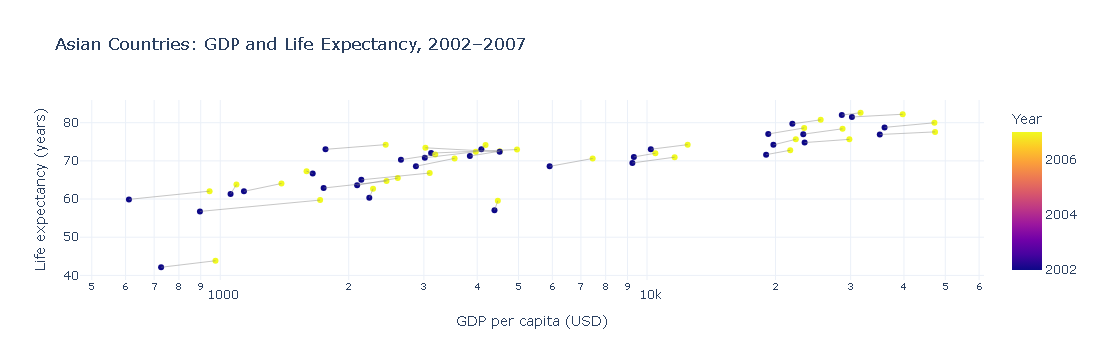

In [3]:

# Task 1 — Scatter: Life expectancy change over time

import plotly.express as px
import plotly.graph_objects as go

# Choose Asia (any continent except Africa)
continent_df = df.loc[
    (df["continent"] == "Asia") &
    (df["year"].isin([2002, 2007]))
].copy()

# Scatter plot: GDP per capita vs life expectancy
fig = px.scatter(
    continent_df,
    x="gdpPercap",
    y="lifeExp",
    color="year",
    color_discrete_map={
        2002: "#4C78A8",
        2007: "#F58518"
    },
    hover_name="country",
    size_max=12,
    title="Asian Countries: GDP and Life Expectancy, 2002–2007",
    labels={
        "gdpPercap": "GDP per capita (USD)",
        "lifeExp": "Life expectancy (years)",
        "year": "Year"
    }
)

# Connect each country's 2002 and 2007 points to show direction of change
for country in continent_df["country"].unique():
    country_data = continent_df[
        continent_df["country"] == country
    ].sort_values("year")

    if len(country_data) == 2:
        fig.add_trace(
            go.Scatter(
                x=country_data["gdpPercap"],
                y=country_data["lifeExp"],
                mode="lines",
                line=dict(color="gray", width=1),
                opacity=0.45,
                showlegend=False,
                hoverinfo="skip"
            )
        )

fig.update_layout(
    template="plotly_white",
    legend_title_text="Year"
)

fig.update_xaxes(type="log")
fig.show()


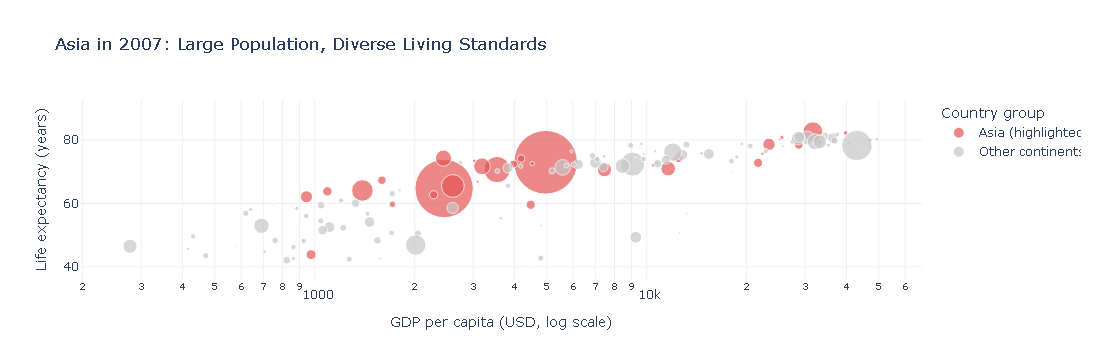

In [4]:

# Task 2 — Bubble chart: Tell a story

import plotly.express as px

# Use the full 2007 dataset
df_2007 = df.loc[df["year"] == 2007].copy()

# Highlight Asia and show all other continents in grey
highlight_continent = "Asia"

df_2007["Group"] = df_2007["continent"].apply(
    lambda continent: "Asia (highlighted)"
    if continent == highlight_continent
    else "Other continents"
)

fig = px.scatter(
    df_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    color="Group",
    color_discrete_map={
        "Asia (highlighted)": "#E45756",
        "Other continents": "#C7C7C7"
    },
    hover_name="country",
    size_max=45,
    title="Asia in 2007: Large Population, Diverse Living Standards",
    labels={
        "gdpPercap": "GDP per capita (USD, log scale)",
        "lifeExp": "Life expectancy (years)",
        "pop": "Population",
        "Group": "Country group"
    }
)

# Use a logarithmic scale for GDP per capita
fig.update_xaxes(type="log")

# Add an annotation explaining the highlighted group's story
fig.add_annotation(
    x=2500,
    y=68,
    text=(
        "Asia shows wide differences in income<br>"
        "and life expectancy across countries."
    ),
    showarrow=True,
    arrowhead=2,
    ax=100,
    ay=-60,
    bgcolor="white",
    bordercolor="#E45756",
    borderwidth=1
)

fig.update_layout(
    template="plotly_white",
    legend_title_text="Country group"
)

fig.show()
